# 💰 Personal Finance Data Pipeline & Interactive Dashboard

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wachirapatsiri/personal-finance-pipeline-dashboard/blob/main/personal_finance_pipeline_dashboard.ipynb)

**Data Pipeline** (ทำความสะอาด + ตรวจสอบคุณภาพ + จัดหมวดหมู่ด้วย Fuzzy Matching) และ **Dashboard (Gradio)** ไว้ด้วยกัน
ฟังก์ชันทั้งหมดถูกเขียนไว้ที่เดียว แล้วใช้ซ้ำทั้งในส่วนวิเคราะห์ใน Notebook และส่วนหน้าเว็บ

## ปัญหาที่แก้
สรุปรายรับ-รายจ่ายจาก bank statement แบบ CSV ด้วยมือใช้เวลานานและผิดพลาดง่าย เพราะข้อมูลจริงมักสกปรก เช่น ชื่อร้านสะกดไม่เหมือนกัน (`Grab` / `GRABB` / `grab ride`), วันที่หลายฟอร์แมต (รวมปี พ.ศ. และเลขไทย), ยอดเงินมีสัญลักษณ์ `฿` หรือ comma, ค่าว่าง, ค่าติดลบ และรายการซ้ำ

## ขั้นตอนของ Pipeline
```
CSV ดิบ ─► ตัด transaction_id ซ้ำ ─► กู้/ตรวจยอดด้วย balance ─► ตรวจค่าว่าง/ยอดเงิน/ค่าติดลบ
        ─► แปลงวันที่ (3 ฟอร์แมต + พ.ศ. + เลขไทย) ─► Fuzzy Matching จัดหมวดหมู่
        ─► Cross-check กับคอลัมน์ type ─► รายงานคุณภาพข้อมูล + Dashboard
```

## รูปแบบไฟล์ CSV
| คอลัมน์ | จำเป็น | หมายเหตุ |
|---|---|---|
| `transaction_id` | ✅ | รหัสรายการ (ซ้ำจะเก็บรายการแรก) |
| `date` | ✅ | `YYYY-MM-DD`, `DD/MM/YYYY`, `DD-MM-YYYY` (รองรับ พ.ศ. และเลขไทย) |
| `description` | ✅ | ชื่อร้าน/รายการ |
| `amount` | ✅ | ยอดเงิน (รองรับ `฿`, comma) |
| `type` | ไม่บังคับ | `รายรับ` / `รายจ่าย` ใช้ cross-check กับหมวดที่ระบบจัดให้ |
| `balance` | ไม่บังคับ | ยอดคงเหลือ ใช้กู้ยอดที่หายไปได้ ถ้า balance ต่อเนื่องกันจริง |

## วิธีรัน
1. รันทุก cell ตามลำดับ (Colab: *Runtime ▸ Run all*)
2. cell สุดท้ายจะได้ลิงก์ `*.gradio.live` เพื่ออัปโหลด CSV และดู Dashboard

> **ข้อสมมติ:** วันที่รูปแบบ `01-02-2026` ถูกตีเป็น **วัน-เดือน-ปี** เสมอ ข้อมูลในโปรเจกต์นี้เป็น **mock data** ที่สร้างขึ้นเอง โดยใส่ความผิดปกติไว้ตั้งใจเพื่อทดสอบ Pipeline

## 1. Setup

In [1]:
# ติดตั้ง library (gradio>=6 ต้องส่ง theme ผ่าน launch())
!pip install -q "gradio>=6" thefuzz

In [2]:
%matplotlib inline
import os, re, tempfile, unicodedata, urllib.request

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
from matplotlib.figure import Figure
from thefuzz import process, fuzz
import gradio as gr
from IPython.display import display, Markdown

# ====================== Config (แก้ค่าตรงนี้ที่เดียว) ======================
DATA_PATH = 'data/mock_bank_statement_large.csv'   # ไฟล์ตัวอย่าง (large = 3,090 แถว, small = 490 แถว)
DATA_URL = ('https://raw.githubusercontent.com/wachirapatsiri/'
            'personal-finance-pipeline-dashboard/main/data/mock_bank_statement_large.csv')

REQUIRED_COLS = ['transaction_id', 'date', 'description', 'amount']
FUZZY_THRESHOLD = 70           # คะแนนขั้นต่ำ (0-100) ที่ยอมรับว่าเป็นร้านเดียวกัน ต่ำกว่านี้ = 'Others'
NEGATIVE_POLICY = 'exclude'    # ยอดติดลบที่กู้ไม่ได้: 'exclude' = ไม่นับ (ปลอดภัยสุด) | 'abs' = แปลงเป็นค่าบวก
USE_BALANCE_RECONCILIATION = True   # ใช้ส่วนต่างของ balance กู้ยอดที่ว่าง/ติดลบ (ทำงานเฉพาะเมื่อ balance ต่อเนื่องจริง)
BALANCE_CONSISTENCY_MIN = 0.90      # สัดส่วนแถวที่ |amount| ตรงกับส่วนต่าง balance ขั้นต่ำ จึงจะเชื่อถือ balance

assert NEGATIVE_POLICY in ('exclude', 'abs')

In [3]:
# ====================== Helpers ======================
THAI_DIGITS = str.maketrans('๐๑๒๓๔๕๖๗๘๙', '0123456789')


def setup_thai_font():
    """โหลด TH Sarabun New ให้ Matplotlib ถ้าโหลดไม่ได้จะใช้ฟอนต์ไทยที่มีในเครื่องแทน"""
    font_file = 'thsarabunnew-webfont.ttf'
    font_url = ('https://github.com/Phonbopit/sarabun-webfont/raw/master/'
                'fonts/thsarabunnew-webfont.ttf')
    if not os.path.exists(font_file):
        try:
            urllib.request.urlretrieve(font_url, font_file)
        except Exception:
            pass
    if os.path.exists(font_file):
        mpl.font_manager.fontManager.addfont(font_file)
    installed = {f.name for f in mpl.font_manager.fontManager.ttflist}
    families = [f for f in ('TH Sarabun New', 'Loma', 'Tahoma', 'Noto Sans Thai', 'DejaVu Sans') if f in installed]
    mpl.rc('font', family=families or ['DejaVu Sans'], size=14)
    mpl.rc('axes', unicode_minus=False)


def read_csv_safe(path):
    """อ่าน CSV เผื่อไฟล์เป็น utf-8-sig / utf-8 / cp874 (ไฟล์ไทยที่เซฟจาก Excel)"""
    for enc in ('utf-8-sig', 'utf-8', 'cp874'):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError('อ่านไฟล์ไม่ได้ ลองเซฟเป็น CSV UTF-8 แล้วอัปโหลดใหม่')


def norm_text(x):
    """Normalize ข้อความ: Unicode NFKC, ตัดช่องว่างส่วนเกิน, พิมพ์เล็ก (ใช้กับทั้งข้อมูลและ dictionary)"""
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(x))).strip().lower()


setup_thai_font()

## 2. Data Extraction & Exploration
โหลดข้อมูลและดูภาพรวมคุณภาพข้อมูลก่อนลงมือทำความสะอาด

In [4]:
if not os.path.exists(DATA_PATH):
    try:
        os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    except Exception:
        from google.colab import files          # ใช้ได้เฉพาะ Colab
        print('อัปโหลดไฟล์ CSV (transaction_id, date, description, amount)')
        DATA_PATH = next(iter(files.upload()))

raw = read_csv_safe(DATA_PATH)
missing = [c for c in REQUIRED_COLS if c not in raw.columns]
assert not missing, f'ไฟล์ขาดคอลัมน์: {missing}'

print(f'ไฟล์: {DATA_PATH} | {raw.shape[0]:,} แถว x {raw.shape[1]} คอลัมน์')
display(raw.head(10))

ไฟล์: data/mock_bank_statement_large.csv | 3,090 แถว x 7 คอลัมน์


,transaction_id,date,description,type,amount,balance,note
0,TXN02049,06-12-2026,Grabb,รายจ่าย,82.06,139781.63,NaN
1,TXN00826,25-02-2026,ร้านลุงมี ก๋วยเตี๋ยวเรือ,รายจ่าย,888.73,25311.63,NaN
2,TXN01540,13/07/2026,7-elevn,รายจ่าย,261.97,9474.74,NaN
3,TXN02054,2026-04-05,Seven Eleven,รายจ่าย,232.74,-11433.43,NaN
4,TXN00338,2026-01-08,Grab,รายจ่าย,866.63,21604.58,NaN
5,TXN02670,10-10-2026,รายได้ฟรีแลนซ์,รายรับ,777.98,99964.07,NaN
6,TXN01241,18-07-2026,ดอกเบี้ยเงินฝาก,รายรับ,52.37,14509.34,NaN
7,TXN02299,26/03/2026,lotus,รายจ่าย,546.22,8545.18,NaN
8,TXN02927,2026-12-04,Shopee Thailand,รายจ่าย,96.10,131644.43,NaN
9,TXN01571,17-03-2026,การไฟฟ้าส่วนภูมิภาค,รายจ่าย,580.48,9613.91,NaN


In [5]:
# ภาพรวมคุณภาพข้อมูลดิบ
amount_text = raw['amount'].astype('string')
summary = pd.Series({
    'แถวทั้งหมด': len(raw),
    'amount ว่าง': int(raw['amount'].isna().sum()),
    'amount ที่มีสัญลักษณ์/comma (เช่น ฿, 3,200.00)': int(amount_text.str.contains(r'[^0-9.\-]', regex=True).fillna(False).sum()),
    'transaction_id ซ้ำ': int(raw.duplicated(subset=['transaction_id']).sum()),
    'ชื่อร้านที่ต่างกัน (ดิบ)': raw['description'].nunique(),
    'ชื่อร้านที่ต่างกัน (หลังตัดช่องว่าง/พิมพ์เล็ก)': raw['description'].astype(str).map(norm_text).nunique(),
}, name='จำนวน')
display(summary.to_frame())

print('รูปแบบวันที่ที่พบ (9 = ตัวเลข):')
display(raw['date'].astype(str).str.replace(r'[0-9๐-๙]', '9', regex=True).value_counts().to_frame('จำนวน'))

,จำนวน
แถวทั้งหมด,3090
amount ว่าง,170
"amount ที่มีสัญลักษณ์/comma (เช่น ฿, 3,200.00)",0
transaction_id ซ้ำ,90
ชื่อร้านที่ต่างกัน (ดิบ),46
ชื่อร้านที่ต่างกัน (หลังตัดช่องว่าง/พิมพ์เล็ก),27


รูปแบบวันที่ที่พบ (9 = ตัวเลข):


,จำนวน
date,
99-99-9999,1045
9999-99-99,1036
99/99/9999,1009


## 3. Merchant Dictionary (ตั้งค่าหมวดหมู่ที่เดียว)
`MERCHANTS` เก็บ **ชื่อมาตรฐาน → (ชื่อที่ใช้แสดงผล, หมวดหมู่)** ไว้ที่เดียว เพื่อให้ชื่อในกราฟ/ตาราง/KPI ตรงกันเสมอ

- **ชื่อที่สะกดผิดเล็กน้อย** (`grabb`, `lotuss`, `7-elevn`) ให้ Fuzzy Matching จัดการเอง
- **ตัวย่อที่ Fuzzy ต่อไม่ถึง** (`7-11`, `การไฟฟ้าฯ`) ต้องเพิ่มเป็น alias ใน dictionary
- รายรับ (`Income`) รวมเงินโอนเข้าทั้งหมด ส่วนรายจ่ายคือทุกหมวดที่เหลือ (รวม `Others` และ `Transfer Out`)

In [6]:
MERCHANTS = {
    # ---- ซูเปอร์มาร์เก็ต / ตลาด ----
    '7-eleven': ('7-Eleven', 'Supermarket'),
    'seven eleven': ('7-Eleven', 'Supermarket'),
    '7-11': ('7-Eleven', 'Supermarket'),
    'lotus': ("Lotus's", 'Supermarket'),
    "lotus's": ("Lotus's", 'Supermarket'),
    'ตลาดนัดหน้าหอ': ('ตลาดนัดหน้าหอ', 'Supermarket'),
    # ---- การเดินทาง ----
    'grab': ('Grab', 'Transportation'),
    'วินมอเตอร์ไซค์': ('วินมอเตอร์ไซค์', 'Transportation'),
    'รถเมล์ ขสมก.': ('รถเมล์ ขสมก.', 'Transportation'),
    # ---- ช้อปปิ้ง ----
    'shopee': ('Shopee', 'Online Shopping'),
    'shopee thailand': ('Shopee', 'Online Shopping'),
    'lazada': ('Lazada', 'Online Shopping'),
    'uniqlo': ('Uniqlo', 'Shopping & Fashion'),
    # ---- สาธารณูปโภค / ที่พัก ----
    'true': ('TRUE', 'Utilities'),
    'true corporation': ('TRUE', 'Utilities'),
    'การไฟฟ้าส่วนภูมิภาค': ('การไฟฟ้าส่วนภูมิภาค', 'Utilities'),
    'การไฟฟ้าฯ': ('การไฟฟ้าส่วนภูมิภาค', 'Utilities'),
    'การประปาส่วนภูมิภาค': ('การประปาส่วนภูมิภาค', 'Utilities'),
    'ค่าหอพัก แสงจันทร์อพาร์ตเมนต์': ('ค่าหอพัก', 'Housing'),
    # ---- สุขภาพ / ความงาม ----
    'boots': ('Boots', 'Health & Beauty'),
    # ---- อาหารและเครื่องดื่ม ----
    'starbucks': ('Starbucks', 'Food & Beverage'),
    'amazon café': ('Amazon Café', 'Food & Beverage'),
    'amazon cafe': ('Amazon Café', 'Food & Beverage'),
    'ร้านลุงมี ก๋วยเตี๋ยวเรือ': ('ร้านลุงมี ก๋วยเตี๋ยวเรือ', 'Food & Beverage'),
    'ร้านก๋วยเตี๋ยวป้าแดง': ('ร้านก๋วยเตี๋ยวป้าแดง', 'Food & Beverage'),
    'ร้านส้มตำหน้าม.': ('ร้านส้มตำหน้าม.', 'Food & Beverage'),
    'ร้านข้าวแกงป้านิด': ('ร้านข้าวแกงป้านิด', 'Food & Beverage'),
    'ร้านกาแฟหน้าปากซอย': ('ร้านกาแฟหน้าปากซอย', 'Food & Beverage'),
    'ฟู้ดคอร์ทมหาลัย': ('ฟู้ดคอร์ทมหาลัย', 'Food & Beverage'),
    # ---- บันเทิง ----
    'netflix': ('Netflix', 'Entertainment'),
    'netflix.com': ('Netflix', 'Entertainment'),
    # ---- รายรับ ----
    'รายได้ฟรีแลนซ์': ('รายได้ฟรีแลนซ์', 'Income'),
    'ดอกเบี้ยเงินฝาก': ('ดอกเบี้ยเงินฝาก', 'Income'),
    'เงินคืนภาษี': ('เงินคืนภาษี', 'Income'),
    'ค่าคอมมิชชั่น': ('ค่าคอมมิชชั่น', 'Income'),
    'cashback shopee': ('Cashback Shopee', 'Income'),     # เงินคืนจาก Shopee เป็นรายรับ ไม่ใช่การซื้อของ
    'เงินเดือน': ('เงินเดือน', 'Income'),
    'เงินเดือน/ค่าขนมรายเดือน': ('เงินเดือน', 'Income'),
    'โอนเงินจาก': ('เงินโอน', 'Income'),                  # โอนเงินจาก แม่ / เพื่อน / ใครก็ตาม
    # ---- เงินโอนออก (นับเป็นรายจ่าย) ----
    'โอนเงินให้': ('เงินโอน', 'Transfer Out'),
}

# lookup ที่ normalize แล้ว (กันปัญหาสระ/วรรณยุกต์ไทยที่ Unicode ต่างรูปกัน)
_LOOKUP = {norm_text(k): v for k, v in MERCHANTS.items()}
standard_merchants = list(_LOOKUP)


def classify_flow(category):
    """ใช้นิยามเดียวกันทั้ง KPI, กราฟ และตาราง: Income = รายรับ, นอกนั้น = รายจ่าย"""
    return 'income' if category == 'Income' else 'expense'


def match_and_categorize(name):
    """คืน (ชื่อที่ใช้แสดงผล, หมวดหมู่, คะแนน) — name ต้องผ่าน norm_text มาแล้ว"""
    if name in _LOOKUP:                                  # 1) ตรงเป๊ะ → ใช้เลย (กัน 'cashback shopee' ถูกดึงไปเป็น 'shopee')
        display_name, category = _LOOKUP[name]
        return display_name, category, 100
    scored = process.extract(name, standard_merchants,   # 2) Fuzzy: คะแนนเท่ากันให้เลือกคีย์ที่ยาวกว่า (เฉพาะเจาะจงกว่า)
                             scorer=fuzz.token_set_ratio, limit=None)
    key, score = max(scored, key=lambda x: (x[1], len(x[0])))
    if score < FUZZY_THRESHOLD:
        return name, 'Others', score
    display_name, category = _LOOKUP[key]
    return display_name, category, score

## 4. Pipeline: `validate_and_clean`
ทุกแถวที่ถูกตัดหรือแก้จะถูกบันทึกลง `flagged_df` พร้อมเหตุผลและเลขบรรทัดในไฟล์ต้นฉบับ เพื่อให้ตรวจย้อนกลับได้ (audit trail)

| ลำดับ | ตรวจอะไร | ทำอย่างไร |
|---|---|---|
| 1 | `transaction_id` ซ้ำ | เก็บรายการแรก ตัดที่เหลือ |
| 2 | `amount` ว่าง/ติดลบ | ถ้า `balance` ต่อเนื่องกันจริง กู้ยอดจากส่วนต่างของ balance, ถ้าไม่ได้ทำตาม `NEGATIVE_POLICY` |
| 3 | ค่าว่างใน id / date / description | ตัดออก |
| 4 | `amount` ไม่ใช่ตัวเลข | ตัดออก (แปลง `฿`, comma, เลขไทยให้ก่อน) |
| 5 | วันที่ | แปลง 3 ฟอร์แมต + ปี พ.ศ. + เลขไทย, วันที่ที่ไม่มีจริง (`31-02`, `0000-00-00`) ตัดออก |
| 6 | จัดหมวดหมู่ | Fuzzy Matching เฉพาะชื่อที่ไม่ซ้ำ แล้ว map กลับ (เร็วกว่า `apply` ทีละแถวมาก) |
| 7 | Cross-check | เทียบ `flow` ที่ระบบจัดกับคอลัมน์ `type` ในไฟล์ (ถ้ามี) ไม่ตรงให้ flag แต่ยังคงไว้ |

In [7]:
def normalize_date_text(s):
    """เลขไทย → เลขอารบิก และปี พ.ศ. (24xx-29xx) → ค.ศ. คืน (ข้อความ, mask ที่เป็น พ.ศ.)"""
    t = s.astype('string').str.strip().str.translate(THAI_DIGITS)
    be_year = r'(?<![0-9])(2[4-9][0-9]{2})(?![0-9])'
    is_be = t.str.contains(r'(?<![0-9])2[4-9][0-9]{2}(?![0-9])', regex=True).fillna(False).astype(bool)
    t = t.str.replace(be_year, lambda m: str(int(m.group(1)) - 543), regex=True)
    return t, is_be


def parse_date_robust(t):
    """ลองหลายฟอร์แมตตามลำดับ (วัน-เดือน-ปี เสมอ) ค่าที่แปลงไม่ได้จะเป็น NaT"""
    result = pd.Series(pd.NaT, index=t.index, dtype='datetime64[ns]')
    for fmt in ('%Y-%m-%d', '%d/%m/%Y', '%d-%m-%Y'):
        remaining = result.isna()
        if not remaining.any():
            break
        result.loc[remaining] = pd.to_datetime(t.loc[remaining], format=fmt, errors='coerce')
    return result


def validate_and_clean(raw_df):
    """
    คืนค่า (df_clean, report: dict, flagged_df)
    flagged_df = ทุกแถวที่ถูกตัด/แก้/ต้องตรวจสอบ พร้อม validation_issue, action และเลขบรรทัดใน CSV ต้นฉบับ
    """
    df = raw_df.copy()
    df['source_row'] = np.arange(len(df)) + 2          # บรรทัดที่ 1 ของไฟล์ = header
    df['amount_raw'] = df['amount']
    total_raw = len(df)
    has_type = 'type' in df.columns
    has_balance = 'balance' in df.columns
    flagged = []

    def flag(mask, reason, action, fixed=None):
        rows = df.loc[mask, ['source_row', 'transaction_id', 'date', 'description', 'amount_raw']].copy()
        if len(rows):
            rows['validation_issue'] = reason
            rows['action'] = action
            rows['fixed_value'] = fixed.loc[mask] if fixed is not None else np.nan
            flagged.append(rows)
        return int(mask.sum())

    # ---- 1) transaction_id ซ้ำ (เก็บรายการแรก) ----
    dup_mask = df['transaction_id'].notna() & df.duplicated(subset=['transaction_id'], keep='first')
    n_dup = flag(dup_mask, 'transaction_id ซ้ำ (เก็บรายการแรกไว้)', 'ตัดออก')
    df = df[~dup_mask]

    # ---- 2) แปลง amount เป็นตัวเลข (ตัด ฿ , และเลขไทย) ----
    df['amount'] = pd.to_numeric(
        df['amount'].astype('string').str.translate(THAI_DIGITS).str.replace(r'[^0-9.\-]', '', regex=True),
        errors='coerce').astype(float)

    # ---- 3) ใช้ส่วนต่างของ balance กู้ยอดที่ว่าง/ติดลบ (เฉพาะเมื่อ balance ต่อเนื่องกันจริง) ----
    balance_consistency, recon_active = np.nan, False
    n_recovered = n_neg_fixed = 0
    if USE_BALANCE_RECONCILIATION and has_balance:
        implied = pd.to_numeric(df['balance'], errors='coerce').diff().abs().round(2)
        comparable = df['amount'].notna() & implied.notna()
        if comparable.sum() >= 20:
            matches = ((df['amount'].abs().round(2) - implied).abs() < 0.01)[comparable]
            balance_consistency = float(matches.mean())
            recon_active = balance_consistency >= BALANCE_CONSISTENCY_MIN
        if recon_active:
            rec_mask = df['amount'].isna() & implied.notna()
            n_recovered = flag(rec_mask, 'amount ว่าง/แปลงไม่ได้ → กู้จากส่วนต่าง balance', 'แก้อัตโนมัติ', fixed=implied)
            df.loc[rec_mask, 'amount'] = implied[rec_mask]
            fix_mask = (df['amount'] < 0) & ((df['amount'].abs() - implied).abs() < 0.01)
            n_neg_fixed = flag(fix_mask, 'amount ติดลบ แต่ตรงกับส่วนต่าง balance → แปลงเป็นค่าบวก', 'แก้อัตโนมัติ', fixed=df['amount'].abs())
            df.loc[fix_mask, 'amount'] = df.loc[fix_mask, 'amount'].abs()

    # ---- 4) ค่าว่างในคอลัมน์จำเป็น / amount ที่กู้ไม่ได้ ----
    null_mask = df[['transaction_id', 'date', 'description']].isna().any(axis=1)
    n_null = flag(null_mask, 'มีค่าว่างใน transaction_id/date/description', 'ตัดออก')
    df = df[~null_mask]

    amount_na = df['amount'].isna()
    n_amount_null = flag(amount_na & df['amount_raw'].isna(), 'amount ว่าง (กู้ค่าไม่ได้)', 'ตัดออก')
    n_invalid_amount = flag(amount_na & df['amount_raw'].notna(), 'amount ไม่ใช่ตัวเลข', 'ตัดออก')
    df = df[~amount_na]

    # ---- 5) ยอดติดลบที่เหลือ ตาม NEGATIVE_POLICY ----
    neg_mask = df['amount'] < 0
    n_negative = int(neg_mask.sum())
    if NEGATIVE_POLICY == 'exclude':
        flag(neg_mask, 'amount ติดลบ (ไม่นำมาคำนวณ ควรตรวจต้นฉบับ)', 'ตัดออก')
        df = df[~neg_mask]
        n_negative_dropped = n_negative
    else:
        flag(neg_mask, 'amount ติดลบ → แปลงเป็นค่าบวก (ควรตรวจต้นฉบับ)', 'แก้อัตโนมัติ', fixed=df['amount'].abs())
        df.loc[neg_mask, 'amount'] = df.loc[neg_mask, 'amount'].abs()
        n_negative_dropped = 0

    # ---- 6) วันที่ ----
    date_text, is_be = normalize_date_text(df['date'])
    df['date_cleaned'] = parse_date_robust(date_text)
    invalid_date = df['date_cleaned'].isna()
    n_invalid_date = flag(invalid_date, 'วันที่ไม่ถูกต้อง/ไม่มีอยู่จริง', 'ตัดออก')
    valid_date = ~invalid_date
    is_iso = date_text.str.match(r'^[0-9]{4}-[0-9]{2}-[0-9]{2}$').fillna(False).astype(bool) & ~is_be
    n_date_reformatted = int((valid_date & ~is_iso).sum())
    n_date_be = int((valid_date & is_be).sum())
    df = df[valid_date]

    # ---- 7) จัดหมวดหมู่ (Fuzzy เฉพาะชื่อที่ไม่ซ้ำ) ----
    n_others = n_type_mismatch = 0
    others_merchants = []
    if len(df):
        df['description_cleaned'] = df['description'].astype(str).map(norm_text)
        mapping = {name: match_and_categorize(name) for name in df['description_cleaned'].unique()}
        df['description_standard'] = df['description_cleaned'].map(lambda n: mapping[n][0])
        df['category'] = df['description_cleaned'].map(lambda n: mapping[n][1])
        df['match_score'] = df['description_cleaned'].map(lambda n: mapping[n][2])
        df['flow'] = df['category'].map(classify_flow)
        is_other = df['category'] == 'Others'
        n_others = int(is_other.sum())
        others_merchants = df.loc[is_other, 'description_standard'].value_counts().head(10).index.tolist()

        # ---- 8) Cross-check กับคอลัมน์ type (ถ้ามี) ----
        if has_type:
            type_flow = df['type'].astype('string').str.strip().map({'รายรับ': 'income', 'รายจ่าย': 'expense'})
            mismatch = (type_flow.notna() & (type_flow != df['flow'])).fillna(False).astype(bool)
            n_type_mismatch = flag(mismatch, 'type ในไฟล์ไม่ตรงกับหมวดที่ระบบจัด (ตรวจ dictionary)', 'ตรวจสอบ (คงไว้)')
    else:
        for col in ('description_standard', 'category', 'flow'):
            df[col] = pd.Series(dtype=object)
        df['match_score'] = pd.Series(dtype=float)

    flagged_cols = ['source_row', 'transaction_id', 'date', 'description', 'amount_raw',
                    'validation_issue', 'action', 'fixed_value']
    flagged_df = (pd.concat(flagged, ignore_index=True).sort_values('source_row').reset_index(drop=True)
                  if flagged else pd.DataFrame(columns=flagged_cols))

    report = {
        'total_raw': total_raw,
        'total_clean': len(df),
        'duplicate_id': n_dup,
        'null_required': n_null + n_amount_null,
        'invalid_amount': n_invalid_amount,
        'negative_amount': n_negative_dropped,
        'invalid_date': n_invalid_date,
        'amount_recovered': n_recovered,
        'negative_fixed': n_neg_fixed + (n_negative if NEGATIVE_POLICY == 'abs' else 0),
        'date_reformatted': n_date_reformatted,
        'date_buddhist': n_date_be,
        'type_mismatch': n_type_mismatch,
        'others_rows': n_others,
        'others_merchants': others_merchants,
        'balance_consistency': balance_consistency,
        'balance_reconciled': recon_active,
    }
    dropped = (report['duplicate_id'] + report['null_required'] + report['invalid_amount']
               + report['negative_amount'] + report['invalid_date'])
    assert total_raw == len(df) + dropped, 'จำนวนแถวไม่สมดุล: ตรวจ logic การตัดแถว'

    return df, report, flagged_df

## 5. ทดสอบฟังก์ชันหลัก (Unit tests)
ทดสอบเคสที่เคยพลาดง่าย ถ้า assert ผ่านทั้งหมดแปลว่าตรรกะยังถูกต้องหลังแก้โค้ด

In [8]:
# --- Fuzzy Matching ---
cases = {
    'grabb': ('Grab', 'Transportation'),
    'grab ride': ('Grab', 'Transportation'),
    'lotuss': ("Lotus's", 'Supermarket'),
    '7-elevn': ('7-Eleven', 'Supermarket'),
    '7-11': ('7-Eleven', 'Supermarket'),
    'starbucks coffee': ('Starbucks', 'Food & Beverage'),
    'true corp.': ('TRUE', 'Utilities'),
    'การไฟฟ้าฯ': ('การไฟฟ้าส่วนภูมิภาค', 'Utilities'),
    'cashback shopee': ('Cashback Shopee', 'Income'),     # ต้องไม่ถูกดึงไปเป็น 'shopee'
    'โอนเงินจาก แม่': ('เงินโอน', 'Income'),
    'โอนเงินให้ เพื่อน': ('เงินโอน', 'Transfer Out'),
}
for name, expected in cases.items():
    got = match_and_categorize(norm_text(name))[:2]
    assert got == expected, f'{name!r}: ได้ {got} แต่คาดหวัง {expected}'

assert match_and_categorize(norm_text('xyz unknown store'))[1] == 'Others'

# --- วันที่ ---
test_dates = pd.Series(['2026-01-08', '13/07/2026', '06-12-2026', '๒๙/๐๑/๒๕๖๙', '31-02-2026', '0000-00-00', '32/13/2026'])
parsed = parse_date_robust(normalize_date_text(test_dates)[0])
assert parsed.iloc[:4].tolist() == [pd.Timestamp('2026-01-08'), pd.Timestamp('2026-07-13'),
                                    pd.Timestamp('2026-12-06'), pd.Timestamp('2026-01-29')]
assert parsed.iloc[4:].isna().all()          # วันที่ที่ไม่มีอยู่จริงต้องเป็น NaT

print('✅ ทุกเคสผ่าน')

✅ ทุกเคสผ่าน


## 6. รัน Pipeline

In [9]:
df, report, df_flagged = validate_and_clean(raw)

# ฟังก์ชันสร้างข้อความรายงาน/KPI (ใช้ร่วมกับ Dashboard)
def build_validation_report_md(report):
    pct = report['total_clean'] / report['total_raw'] * 100 if report['total_raw'] else 0
    lines = [
        '### ผลการตรวจสอบคุณภาพข้อมูล (Data Validation)',
        f"- แถวดิบทั้งหมด: **{report['total_raw']:,}**",
        f"- ผ่านการตรวจสอบและใช้งานได้: **{report['total_clean']:,}** แถว ({pct:.1f}%)",
        '#### ตัดออก',
        f"- transaction_id ซ้ำ: **{report['duplicate_id']:,}** แถว (เก็บรายการแรก)",
        f"- ค่าว่างในคอลัมน์จำเป็น / amount ว่างที่กู้ไม่ได้: **{report['null_required']:,}** แถว",
        f"- amount ไม่ใช่ตัวเลข: **{report['invalid_amount']:,}** แถว",
        f"- amount ติดลบ (ไม่นำมาคำนวณ): **{report['negative_amount']:,}** แถว",
        f"- วันที่ไม่ถูกต้อง/ไม่มีอยู่จริง: **{report['invalid_date']:,}** แถว",
        '#### แก้ให้อัตโนมัติ (ยังอยู่ในข้อมูล)',
        f"- แปลงวันที่เป็น YYYY-MM-DD: **{report['date_reformatted']:,}** แถว (เป็นปี พ.ศ. {report['date_buddhist']:,} แถว)",
    ]
    if report['balance_reconciled']:
        lines += [
            f"- กู้ amount ที่ว่างจากส่วนต่าง balance: **{report['amount_recovered']:,}** แถว",
            f"- แก้ amount ติดลบให้เป็นบวกโดยอิง balance: **{report['negative_fixed']:,}** แถว",
        ]
    elif report['negative_fixed']:
        lines.append(f"- แปลง amount ติดลบเป็นค่าบวก: **{report['negative_fixed']:,}** แถว")
    lines.append('#### ข้อสังเกต')
    if report['balance_reconciled']:
        lines.append(f"- balance ต่อเนื่องกัน {report['balance_consistency']*100:.1f}% จึงใช้กู้ยอดได้")
    elif not np.isnan(report['balance_consistency']):
        lines.append(f"- balance ต่อเนื่องกันเพียง {report['balance_consistency']*100:.1f}% จึงไม่ใช้กู้ยอด")
    if 'type_mismatch' in report:
        lines.append(f"- type ในไฟล์ไม่ตรงกับหมวดที่ระบบจัด: **{report['type_mismatch']:,}** แถว")
    lines.append(f"- จัดหมวดไม่ได้ (Others): **{report['others_rows']:,}** แถว"
                 + (f" เช่น {', '.join(report['others_merchants'])}" if report['others_merchants'] else ''))
    return '\n'.join(lines)


def build_kpi_md(d, report):
    income = d.loc[d['flow'] == 'income', 'amount'].sum()
    expense = d.loc[d['flow'] == 'expense', 'amount'].sum()
    top_cat = d[d['flow'] == 'expense'].groupby('category')['amount'].sum().sort_values(ascending=False)
    top_line = (f"- หมวดที่ใช้เงินมากที่สุด: **{top_cat.index[0]}** ({top_cat.iloc[0]:,.2f} บาท)"
                if len(top_cat) else '- หมวดที่ใช้เงินมากที่สุด: ไม่มีรายจ่ายในข้อมูล')
    return (f"### สรุปภาพรวม\n"
            f"- รายรับรวม (รวมเงินโอนเข้า): **{income:,.2f}** บาท\n"
            f"- รายจ่ายรวม (รวมเงินโอนออก): **{expense:,.2f}** บาท\n"
            f"- รายรับ - รายจ่าย (เงินสดเปลี่ยนแปลงสุทธิ): **{income - expense:,.2f}** บาท\n"
            f"- จำนวนรายการที่ใช้งานได้: **{len(d):,}** รายการ (จากทั้งหมด {report['total_raw']:,} แถว)\n"
            f"{top_line}")


display(Markdown(build_validation_report_md(report)))

### ผลการตรวจสอบคุณภาพข้อมูล (Data Validation)
- แถวดิบทั้งหมด: **3,090**
- ผ่านการตรวจสอบและใช้งานได้: **2,836** แถว (91.8%)
#### ตัดออก
- transaction_id ซ้ำ: **90** แถว (เก็บรายการแรก)
- ค่าว่างในคอลัมน์จำเป็น / amount ว่างที่กู้ไม่ได้: **164** แถว
- amount ไม่ใช่ตัวเลข: **0** แถว
- amount ติดลบ (ไม่นำมาคำนวณ): **0** แถว
- วันที่ไม่ถูกต้อง/ไม่มีอยู่จริง: **0** แถว
#### แก้ให้อัตโนมัติ (ยังอยู่ในข้อมูล)
- แปลงวันที่เป็น YYYY-MM-DD: **1,889** แถว (เป็นปี พ.ศ. 0 แถว)
#### ข้อสังเกต
- balance ต่อเนื่องกันเพียง 0.0% จึงไม่ใช้กู้ยอด
- type ในไฟล์ไม่ตรงกับหมวดที่ระบบจัด: **0** แถว
- จัดหมวดไม่ได้ (Others): **0** แถว

In [10]:
# แถวที่ถูกตัด/แก้ทั้งหมด สรุปตามสาเหตุ และตัวอย่างแถวที่ถูก flag
display(df_flagged.groupby(['validation_issue', 'action']).size().rename('จำนวนแถว').reset_index())
display(df_flagged.head(10))

,validation_issue,action,จำนวนแถว
0,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,164
1,transaction_id ซ้ำ (เก็บรายการแรกไว้),ตัดออก,90


,source_row,transaction_id,date,description,amount_raw,validation_issue,action,fixed_value
0,51,TXN02632,16/02/2026,LOTUS,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN
1,100,TXN01286,2026-04-23,lotus,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN
2,103,TXN02651,2026-03-18,TRUE,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN
3,162,TXN02573,30-05-2026,การไฟฟ้าส่วนภูมิภาค,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN
4,197,TXN02793,12-05-2026,Grabb,316.91,transaction_id ซ้ำ (เก็บรายการแรกไว้),ตัดออก,NaN
5,214,TXN01885,2026-09-26,Grab,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN
6,240,TXN02820,18-07-2026,cashback shopee,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN
7,244,TXN02359,2026-03-28,โอนเงินจาก แม่,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN
8,263,TXN01183,28-07-2026,Grabb,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN
9,274,TXN00419,2026-01-09,lotus,NaN,amount ว่าง (กู้ค่าไม่ได้),ตัดออก,NaN


In [11]:
# ผลการจัดหมวดหมู่: ชื่อร้านดิบ → ชื่อมาตรฐาน (ดูคะแนน Fuzzy ที่ต่ำที่สุดเพื่อเช็กความถูกต้อง)
name_map = (df.groupby(['description_cleaned', 'description_standard', 'category'])
              .agg(rows=('amount', 'size'), score=('match_score', 'min'))
              .reset_index().sort_values('score'))
print(f"ชื่อร้านที่ไม่ซ้ำ {len(name_map)} ชื่อ → ชื่อมาตรฐาน {df['description_standard'].nunique()} ชื่อ")
display(name_map.head(12))

ชื่อร้านที่ไม่ซ้ำ 27 ชื่อ → ชื่อมาตรฐาน 17 ชื่อ


,description_cleaned,description_standard,category,rows,score
6,grabb,Grab,Transportation,114,89
9,lotuss,Lotus's,Supermarket,125,92
1,7-elevn,7-Eleven,Supermarket,116,93
2,boots thailand,Boots,Health & Beauty,113,100
3,cashback shopee,Cashback Shopee,Income,75,100
4,grab,Grab,Transportation,116,100
5,grab ride,Grab,Transportation,127,100
0,7-eleven,7-Eleven,Supermarket,121,100
7,lotus,Lotus's,Supermarket,104,100
8,lotus's,Lotus's,Supermarket,106,100


In [12]:
# ตารางที่ส่งต่อให้ Dashboard (เฉพาะคอลัมน์ที่ใช้)
final_columns = ['transaction_id', 'date_cleaned', 'description_standard', 'category', 'flow', 'amount']
df_clean_final = df[final_columns].sort_values('date_cleaned').reset_index(drop=True)
display(df_clean_final.head())

,transaction_id,date_cleaned,description_standard,category,flow,amount
0,TXN00953,2026-01-01,7-Eleven,Supermarket,expense,358.69
1,TXN01895,2026-01-01,การไฟฟ้าส่วนภูมิภาค,Utilities,expense,549.19
2,TXN02173,2026-01-01,7-Eleven,Supermarket,expense,788.70
3,TXN02775,2026-01-01,Boots,Health & Beauty,expense,35.89
4,TXN00019,2026-01-02,ค่าคอมมิชชั่น,Income,income,1463.45


## 7. Visualization
ทุกฟังก์ชันรับ DataFrame ที่ผ่าน pipeline แล้วคืนค่าเป็น `Figure` เพื่อให้ใช้ซ้ำได้ทั้งใน Notebook และ Gradio (กราฟรายจ่ายทั้งหมดกรองเฉพาะ `flow == 'expense'`)

In [13]:
INCOME_COLOR, EXPENSE_COLOR = '#2a9d8f', '#e76f51'


def fig_trend(d):
    d = d.copy()
    d['year_month'] = d['date_cleaned'].dt.to_period('M').astype(str)
    d['flow_label'] = d['flow'].map({'income': 'รายรับ', 'expense': 'รายจ่าย'})
    trend = d.groupby(['year_month', 'flow_label'])['amount'].sum().reset_index()
    fig = Figure(figsize=(11, 5)); ax = fig.subplots()
    sns.lineplot(data=trend, x='year_month', y='amount', hue='flow_label', marker='o', linewidth=2.5,
                 palette={'รายรับ': INCOME_COLOR, 'รายจ่าย': EXPENSE_COLOR}, ax=ax)
    ax.set_title('แนวโน้มรายรับ-รายจ่ายรายเดือน')
    ax.set_xlabel('เดือน-ปี'); ax.set_ylabel('ยอดรวม (บาท)'); ax.legend(title='')
    ax.grid(True, linestyle='--', alpha=0.5)
    for lbl in ax.get_xticklabels():
        lbl.set_rotation(45); lbl.set_ha('right')
    fig.tight_layout()
    return fig


def fig_income(d):
    inc = d[d['flow'] == 'income'].copy()
    if inc.empty:
        return None
    inc['year_month'] = inc['date_cleaned'].dt.to_period('M').astype(str)
    monthly = inc.groupby('year_month')['amount'].sum()
    by_source = inc.groupby('description_standard')['amount'].sum().sort_values(ascending=False).head(10)
    fig = Figure(figsize=(13, 5)); axes = fig.subplots(1, 2)
    sns.barplot(x=monthly.index, y=monthly.values, color=INCOME_COLOR, ax=axes[0])
    axes[0].set_title('รายรับรายเดือน'); axes[0].set_xlabel('เดือน-ปี'); axes[0].set_ylabel('ยอดรวม (บาท)')
    for lbl in axes[0].get_xticklabels():
        lbl.set_rotation(45); lbl.set_ha('right')
    sns.barplot(x=by_source.values, y=by_source.index, color=INCOME_COLOR, ax=axes[1])
    axes[1].set_title('รายรับแยกตามแหล่งที่มา'); axes[1].set_xlabel('ยอดรวม (บาท)'); axes[1].set_ylabel('')
    fig.tight_layout()
    return fig


def fig_pie(d):
    summary = d[d['flow'] == 'expense'].groupby('category')['amount'].sum().sort_values(ascending=False)
    fig = Figure(figsize=(7, 6)); ax = fig.subplots()
    ax.pie(summary.values, labels=summary.index, autopct='%1.1f%%', startangle=140,
           colors=sns.color_palette('pastel', len(summary)))
    ax.set_title('สัดส่วนรายจ่ายแยกตามหมวดหมู่')
    fig.tight_layout()
    return fig


def fig_top_amount(d):
    top = (d[d['flow'] == 'expense'].groupby('description_standard')['amount'].sum()
           .sort_values(ascending=False).head(10))
    fig = Figure(figsize=(9, 5)); ax = fig.subplots()
    sns.barplot(x=top.values, y=top.index, color=EXPENSE_COLOR, ax=ax)
    ax.set_title('10 อันดับร้านค้าที่ใช้เงินมากที่สุด (ไม่รวมรายรับ)')
    ax.set_xlabel('ยอดรวม (บาท)'); ax.set_ylabel('')
    fig.tight_layout()
    return fig


def fig_top_count(d):
    top = d[d['flow'] == 'expense']['description_standard'].value_counts().head(10)
    fig = Figure(figsize=(9, 5)); ax = fig.subplots()
    sns.barplot(x=top.values, y=top.index, color='#264653', ax=ax)
    ax.set_title('10 อันดับร้านค้าที่จ่ายเงินบ่อยที่สุด (ไม่รวมรายรับ)')
    ax.set_xlabel('จำนวนครั้ง'); ax.set_ylabel('')
    fig.tight_layout()
    return fig


def fig_validation_summary(report):
    # (ป้ายชื่อ, key, ชนิด): drop = ถูกตัดทิ้ง, fix = แก้ให้อัตโนมัติ, check = ให้ตรวจสอบ (คงไว้)
    items = [
        ('transaction_id ซ้ำ', 'duplicate_id', 'drop'),
        ('ค่าว่าง', 'null_required', 'drop'),
        ('จำนวนเงินผิดรูปแบบ', 'invalid_amount', 'drop'),
        ('จำนวนเงินติดลบ (ตัดออก)', 'negative_amount', 'drop'),
        ('วันที่ไม่ถูกต้อง', 'invalid_date', 'drop'),
        ('กู้ยอดจาก balance', 'amount_recovered', 'fix'),
        ('แก้ยอดติดลบเป็นบวก', 'negative_fixed', 'fix'),
        ('แปลง format วันที่', 'date_reformatted', 'fix'),
        ('type ไม่ตรงหมวด', 'type_mismatch', 'check'),
    ]
    palette = {'drop': '#d62728', 'fix': '#ff7f0e', 'check': '#9467bd'}
    labels = [i[0] for i in items]
    values = [report[i[1]] for i in items]
    colors = ['#2ca02c' if v == 0 else palette[i[2]] for v, i in zip(values, items)]   # เขียว = ไม่พบปัญหา
    fig = Figure(figsize=(9, 5)); ax = fig.subplots()
    bars = ax.barh(labels, values, color=colors)
    ax.bar_label(bars, padding=3)
    ax.invert_yaxis()
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color='#d62728', label='ตัดออก'), Patch(color='#ff7f0e', label='แก้อัตโนมัติ'),
                       Patch(color='#9467bd', label='ตรวจสอบ (คงไว้)'), Patch(color='#2ca02c', label='ไม่พบปัญหา')],
              loc='upper right', fontsize=12)
    ax.set_title('จำนวนแถวที่พบปัญหา/ถูกแก้ไข')
    ax.set_xlabel('จำนวนแถว')
    fig.tight_layout()
    return fig

,category,amount
0,Supermarket,311261.77
1,Utilities,177829.96
2,Transportation,162169.49
3,Food & Beverage,150776.45
4,Online Shopping,119486.12
5,Entertainment,63908.34
6,Health & Beauty,54223.07


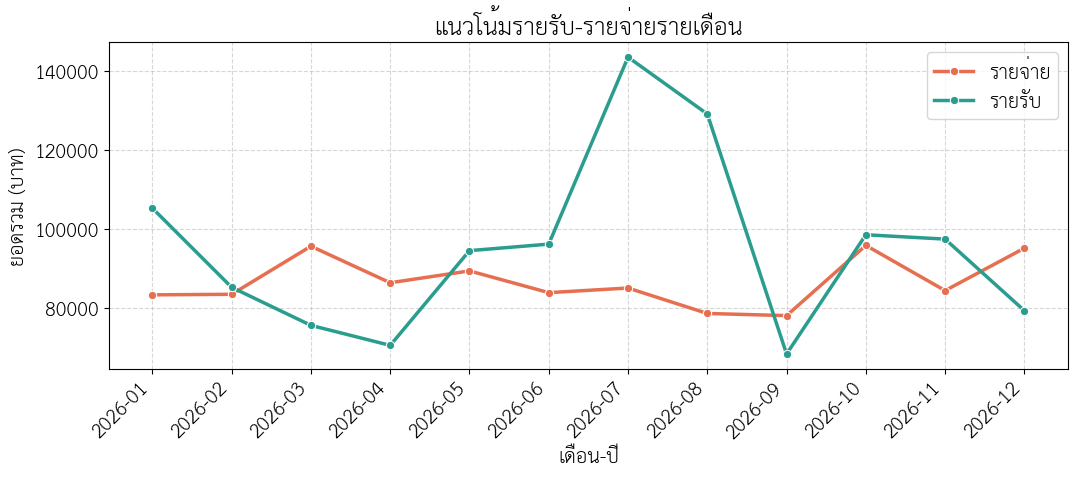

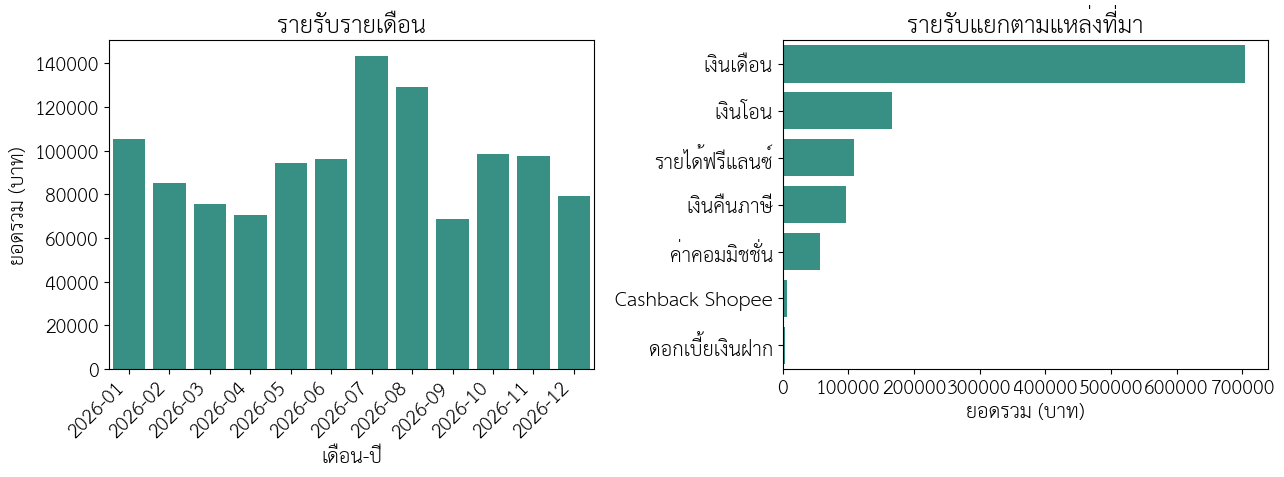

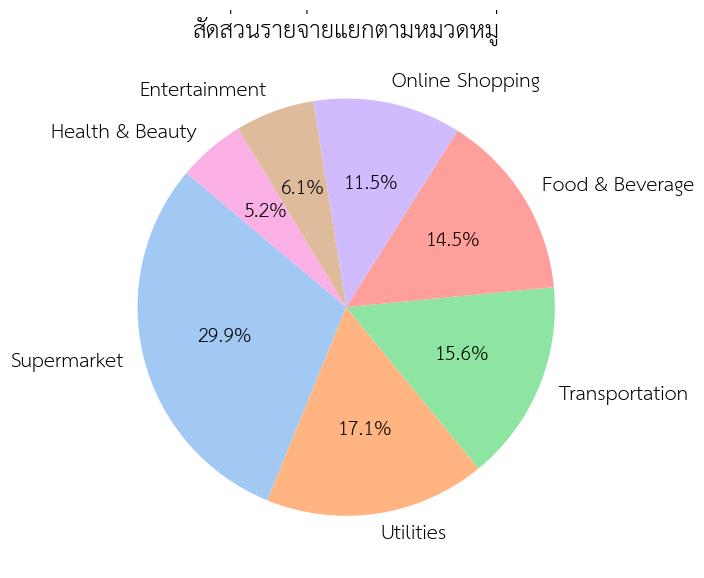

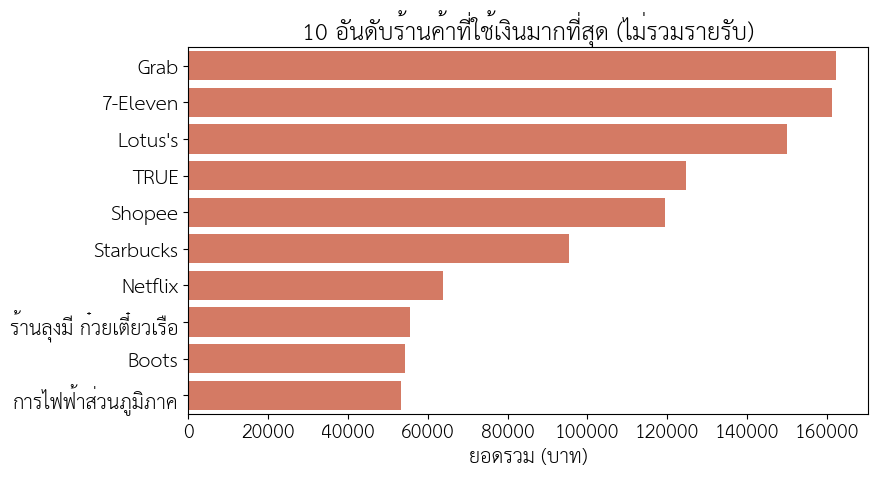

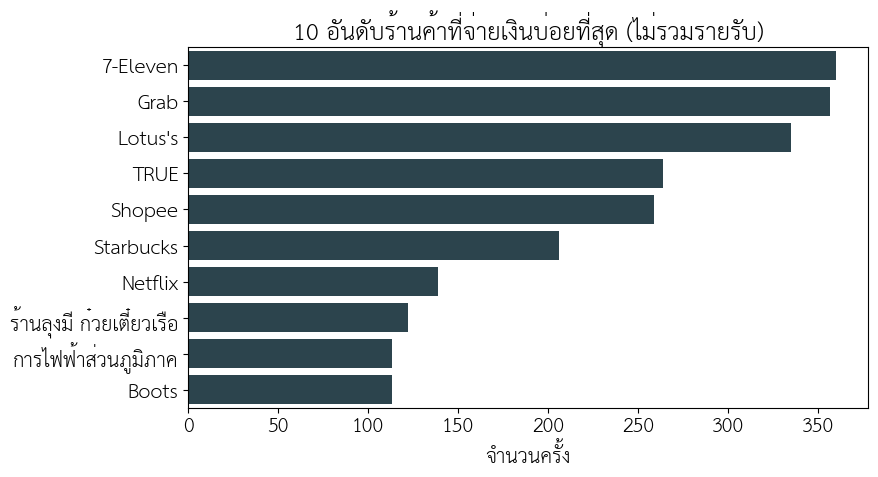

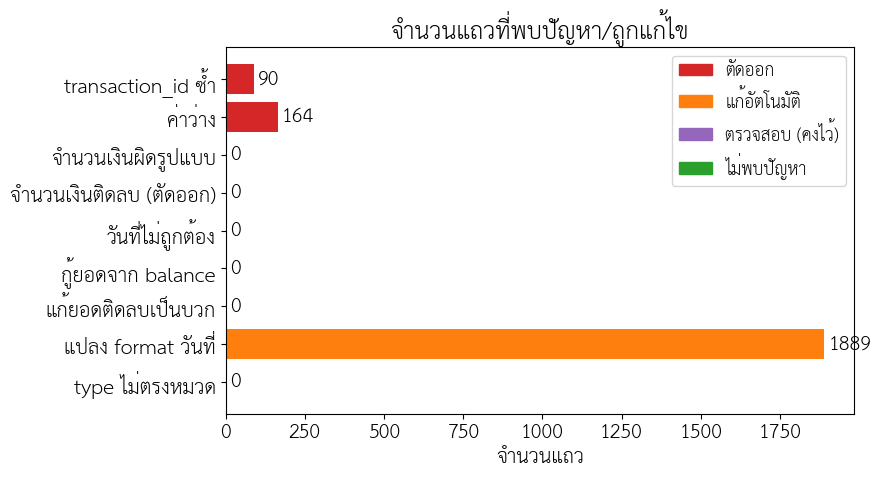

In [14]:
# ยอดรวมแยกตามหมวดหมู่ (เฉพาะรายจ่าย) และกราฟทั้งหมด
category_summary = (df[df['flow'] == 'expense'].groupby('category')['amount'].sum()
                    .sort_values(ascending=False).round(2).reset_index())
display(category_summary)

for make_fig in (fig_trend, fig_income, fig_pie, fig_top_amount, fig_top_count):
    fig = make_fig(df)
    if fig is not None:
        display(fig)
display(fig_validation_summary(report))

## 8. Interactive Dashboard (Gradio)
หน้าเว็บอัปโหลด CSV → รัน `validate_and_clean` → แสดง KPI, กราฟ, รายงานคุณภาพข้อมูล และตารางแถวที่ถูกตัด/แก้พร้อมเหตุผล

- ใช้ฟังก์ชันชุดเดียวกับด้านบนทั้งหมด ไม่มี state แบบ global จึงปลอดภัยเมื่อมีหลายคนใช้พร้อมกัน
- ไฟล์ CSV ที่ Clean แล้วถูกเขียนลง temp file ใหม่ทุกครั้ง ไม่ผูกกับ path ของ Colab
- ลิงก์ `gradio.live` เป็นลิงก์ชั่วคราว (ราว 1 สัปดาห์) ถ้าต้องการแบบถาวรให้ deploy ขึ้น Hugging Face Spaces

In [15]:
OUT_KEYS = ['status', 'kpi', 'cat_table', 'trend', 'pie', 'top_amount', 'top_count',
            'validation_md', 'validation_fig', 'flagged', 'clean_head', 'download', 'income']


def pack(**kw):
    """จัดผลลัพธ์ให้ตรงลำดับ outputs ของ Gradio (key ที่ไม่ส่งมา = None)"""
    return tuple(kw.get(k) for k in OUT_KEYS)


def process_csv(file):
    """รับไฟล์จากหน้าเว็บ → ตรวจสอบคุณภาพข้อมูล → รัน pipeline → ส่งผลไปแสดง Dashboard"""
    if file is None:
        return pack(status='กรุณาเลือกไฟล์ CSV ก่อนกด Submit', kpi='')
    path = file if isinstance(file, str) else file.name
    try:
        raw_in = read_csv_safe(path)
    except Exception as e:
        return pack(status=f'อ่านไฟล์ไม่สำเร็จ: {e}', kpi='')
    missing = [c for c in REQUIRED_COLS if c not in raw_in.columns]
    if missing:
        return pack(status=f"ไฟล์ขาดคอลัมน์: {', '.join(missing)}\nคอลัมน์ที่พบในไฟล์: {', '.join(map(str, raw_in.columns))}", kpi='')
    try:
        d, rep, flagged = validate_and_clean(raw_in)
        validation = dict(validation_md=build_validation_report_md(rep), validation_fig=fig_validation_summary(rep),
                          flagged=flagged if len(flagged) else None)
        if len(d) == 0:
            return pack(status='ไม่มีข้อมูลผ่านการตรวจสอบเลย กรุณาดูรายละเอียดที่แท็บ Validation', kpi='', **validation)

        cat_table = (d[d['flow'] == 'expense'].groupby('category')['amount'].sum()
                     .sort_values(ascending=False).round(2).reset_index()
                     .rename(columns={'category': 'หมวดหมู่', 'amount': 'ยอดรวม (บาท)'}))
        clean_table = d[['transaction_id', 'date_cleaned', 'description_standard', 'category', 'flow', 'amount']] \
            .sort_values('date_cleaned')
        out = tempfile.NamedTemporaryFile(delete=False, suffix='.csv', prefix='cleaned_transactions_')
        out.close()
        clean_table.to_csv(out.name, index=False, encoding='utf-8-sig')

        return pack(status=f"ประมวลผลสำเร็จ: {len(d):,} รายการผ่านการตรวจสอบ (จาก {rep['total_raw']:,} แถว) พร้อมแสดง Dashboard ด้านล่าง",
                    kpi=build_kpi_md(d, rep), cat_table=cat_table,
                    trend=fig_trend(d), pie=fig_pie(d), top_amount=fig_top_amount(d), top_count=fig_top_count(d),
                    clean_head=clean_table.head(100), download=out.name, income=fig_income(d), **validation)
    except Exception as e:
        return pack(status=f'ประมวลผลไม่สำเร็จ: {type(e).__name__}: {e}', kpi='')


with gr.Blocks(title='Dashboard รายรับ-รายจ่าย') as demo:
    gr.Markdown('# ระบบกำกับรายรับ-รายจ่าย')
    gr.Markdown('อัปโหลดไฟล์ CSV (คอลัมน์: `transaction_id, date, description, amount`) แล้วกด Submit เพื่อดู Dashboard')
    with gr.Row():
        file_in = gr.File(label='ไฟล์ CSV', file_types=['.csv'], scale=3)
        submit = gr.Button('Submit', variant='primary', scale=1)
    status = gr.Textbox(label='สถานะ', lines=2)
    with gr.Tabs():
        with gr.Tab('ภาพรวม'):
            kpi_md = gr.Markdown()
            cat_df = gr.Dataframe(label='ยอดรวมรายจ่ายแยกตามหมวดหมู่')
        with gr.Tab('แนวโน้มรายเดือน'):
            p_trend = gr.Plot()
        with gr.Tab('รายรับ'):
            p_income = gr.Plot()
        with gr.Tab('สัดส่วนรายจ่าย'):
            p_pie = gr.Plot()
        with gr.Tab('ร้านค้า'):
            p_amount = gr.Plot()
            p_count = gr.Plot()
        with gr.Tab('ตรวจสอบคุณภาพข้อมูล (Validation)'):
            val_md = gr.Markdown()
            p_validation = gr.Plot()
            flagged_out = gr.Dataframe(label='รายการที่ถูกตัด/แก้ไข พร้อมเหตุผล (validation_issue)')
        with gr.Tab('ข้อมูลที่ทำความสะอาดแล้ว'):
            clean_df = gr.Dataframe(label='100 รายการแรก')
            download = gr.File(label='ดาวน์โหลดไฟล์ CSV ที่ Clean แล้ว')

    # ลำดับ outputs ต้องตรงกับ OUT_KEYS
    submit.click(fn=process_csv, inputs=file_in,
                 outputs=[status, kpi_md, cat_df, p_trend, p_pie, p_amount, p_count,
                          val_md, p_validation, flagged_out, clean_df, download, p_income])

In [ ]:
demo.launch(share=True, debug=False, theme=gr.themes.Soft())